# GPG-003 — Data Preprocessing

**Project:** Gender Wage Gap — Data Mining Final Project
**Dataset:** Current Population Survey (CPS), `CurrentPopulationSurvey.csv` (Kaggle, fedesoriano)
**Task scope (from `docs/GPG-003.md`):** duplicate removal · missing values · outliers (top-coding) ·
categorical encoding · scaling · variable transformation (`log(realhrwage)`) · aggregation / sampling

Every decision is recorded with a rationale in a *decision log* (last section), which is also written to
`docs/results/GPG-003_results.md` so it can be pasted into `docs/GPG-003.md`.

**Outputs** (all under `data/processed/`, git-ignored because of size):

| File | Content | Used by |
|---|---|---|
| `cps_clean.csv.gz` | cleaned, *not* scaled/encoded; engineered target `ln_realhrwage` | GPG-004 (EDA) |
| `cps_model_train.csv.gz`, `cps_model_test.csv.gz` | one-hot encoded + scaled (scaler fitted on train only) | modeling tasks |
| `scaler.joblib`, `model_features.json` | fitted scaler and the feature list | modeling tasks |

Small, committable outputs go to `docs/figures/GPG-003/` and `docs/results/`.

## 0. Setup

In [97]:
import os, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42

# Repo root: this notebook lives in <root>/notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Where is the raw CSV?  (not committed to git — download from Kaggle, see docs/GPG-002.md)
# Override with:  CPS_CSV=/path/to/CurrentPopulationSurvey.csv jupyter lab
candidates = [Path(os.environ["CPS_CSV"])] if "CPS_CSV" in os.environ else []
candidates += [
    ROOT / "data" / "CurrentPopulationSurvey.csv",
    ROOT / "CurrentPopulationSurvey.csv",
    Path.cwd() / "CurrentPopulationSurvey.csv",
    Path.home() / "Downloads" / "CurrentPopulationSurvey.csv",
]
RAW_PATH = next((p for p in candidates if p.exists()), None)
if RAW_PATH is None:
    raise FileNotFoundError(
        "CurrentPopulationSurvey.csv not found. Download it from "
        "https://www.kaggle.com/datasets/fedesoriano/gender-pay-gap-dataset and put it into "
        f"{ROOT / 'data'} (or set the CPS_CSV environment variable)."
    )

PROCESSED = ROOT / "data" / "processed"
FIG_DIR = ROOT / "docs" / "figures" / "GPG-003"
RES_DIR = ROOT / "docs" / "results"
for d in (PROCESSED, FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("Raw file :", RAW_PATH)
print("Root     :", ROOT)

# ---- helpers -------------------------------------------------------------------------------
DECISIONS = []          # decision log -> docs/results/GPG-003_results.md

def log_decision(step, decision, rationale, affected=None):
    DECISIONS.append({"Step": step, "Decision": decision, "Rationale": rationale,
                      "Rows/cols affected": "" if affected is None else affected})

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def downcast(frame):
    """Shrink memory: int/float columns -> smallest safe dtype."""
    for c in frame.select_dtypes(include=["int64", "int32"]).columns:
        frame[c] = pd.to_numeric(frame[c], downcast="integer")
    for c in frame.select_dtypes(include=["float64"]).columns:
        frame[c] = pd.to_numeric(frame[c], downcast="float")
    return frame

Raw file : c:\Users\User\Data-mining-Final-Project\data\CurrentPopulationSurvey.csv
Root     : c:\Users\User\Data-mining-Final-Project


## 1. Load the data

Missing values are the literal string `"NA"` in the CSV (see GPG-002), so we pass `na_values=["NA"]` explicitly.

In [98]:
df = pd.read_csv(RAW_PATH, na_values=["NA"], low_memory=False)
df.columns = df.columns.str.strip().str.lower()
df = df.loc[:, ~df.columns.str.startswith("unnamed")]          # stray index column, if any

# duplicate column names (e.g. "Year" and "year" collapse after lower-casing): report and keep the first one
dup_names = df.columns[df.columns.duplicated()].unique().tolist()
print("Duplicate column names:", dup_names)
for name in dup_names:
    block = df.loc[:, df.columns == name]
    print(f"  {name}: {block.shape[1]} columns, first two identical = {block.iloc[:, 0].equals(block.iloc[:, 1])}")
df = df.loc[:, ~df.columns.duplicated()]

df = downcast(df)

RAW_ROWS, RAW_COLS = df.shape
print(f"Loaded: {RAW_ROWS:,} rows x {RAW_COLS} columns   (GPG-002 reports 344,287 x 234)")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")

REQUIRED = ["year", "sex", "age", "incwage", "hrwage", "realhrwage", "wkswork1", "uhrswork", "potexp", "potexp2"]
missing_required = [c for c in REQUIRED if c not in df.columns]
assert not missing_required, f"Required columns missing from the CSV: {missing_required}"
has = lambda c: c in df.columns
df.head()

Duplicate column names: ['transport']
  transport: 2 columns, first two identical = False
Loaded: 344,287 rows x 233 columns   (GPG-002 reports 344,287 x 234)
Memory: 226 MB


,year,serial,numprec,hwtsupp,gq,region,statefip,metro,metarea,county,farm,month,pernum,wtsupp,relate,age,sex,race,marst,popstat,bpl,yrimmig,citizen,mbpl,fbpl,nativity,hispan,sch,educ99,schlcoll,...,socartother,hotelsrestaurants,medical,education,professional,publicadmin,sumadj_ind,manager,business,financialop,computer,architect,scientist,socialworker,postseceduc,legaleduc,artist,lawyerphysician,healthcare,healthsupport,protective,foodcare,building,sales,officeadmin,farmer,constructextractinstall,production,sumadj_occ,lehs
0,1990,9677,1,"1,052.6500",1,12,36,2.0000,"5,607.0000",NaN,1.0000,3,1,"1,052.6500",101,58,1,3,6,1,NaN,NaN,NaN,NaN,NaN,NaN,1.0000,12.0000,NaN,NaN,...,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1
1,2009,64923,4,971.2000,1,33,5,2.0000,NaN,NaN,NaN,3,4,"1,288.8800",1260,28,1,1,6,1,"9,900.0000",NaN,NaN,"9,900.0000","9,900.0000",1.0000,0.0000,12.0000,10.0000,NaN,...,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1
2,1990,8425,1,"1,622.2800",1,12,36,3.0000,"5,607.0000",NaN,1.0000,3,1,"1,622.2800",101,37,1,1,6,1,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,14.0000,NaN,NaN,...,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1
3,1990,67963,1,"2,689.9099",1,42,6,3.0000,"7,400.0000",NaN,1.0000,3,1,"2,689.9099",101,34,1,1,6,1,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,18.0000,NaN,NaN,...,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
4,1981,38650,9,"1,911.9000",1,31,51,3.0000,"8,840.0000",NaN,1.0000,3,1,"1,911.9000",101,38,1,4,1,1,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,13.0000,NaN,NaN,...,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1


### 1.1 Reproduce the headline numbers from GPG-002
A quick check that we loaded the same data the team described (raw gap on annual wage income).

In [99]:
chk = df.groupby("sex")["incwage"].agg(["count", "mean", "median"])
chk.index = chk.index.map({1: "male", 2: "female"})
print(chk)
m, f = chk.loc["male"], chk.loc["female"]
print(f"\nRaw gap, mean incwage  : {1 - f['mean'] / m['mean']:.1%}   (GPG-002: ~34.1%)")
print(f"Raw gap, median incwage: {1 - f['median'] / m['median']:.1%}   (GPG-002: ~31.4%)")
print("Sex split:", (df["sex"].value_counts(normalize=True).round(4)).to_dict())

         count        mean      median
sex                                   
male    175911 47,729.8609 35,000.0000
female  168376 31,436.9460 24,000.0000

Raw gap, mean incwage  : 34.1%   (GPG-002: ~34.1%)
Raw gap, median incwage: 31.4%   (GPG-002: ~31.4%)
Sex split: {1: 0.5109, 2: 0.4891}


## 2. Duplicate removal

`serial` is a *household* id, so two different people in one household differ in age/sex/wage etc. A fully
identical row (all ~234 columns, including the survey weight `wtsupp`) is therefore almost certainly a duplicated
record, not two real people.

In [100]:
dup_mask = df.duplicated(keep="first")
n_dup = int(dup_mask.sum())
print(f"Exact duplicate rows: {n_dup:,} ({n_dup / len(df):.3%})")
df = df.loc[~dup_mask].reset_index(drop=True)
log_decision("Duplicates", f"Dropped {n_dup:,} exact duplicate rows (kept first occurrence).",
             "A row identical in all columns incl. household id and survey weight is a duplicated record; keeping it "
             "would double-count that worker in every statistic.", f"{n_dup:,} rows")

Exact duplicate rows: 0 (0.000%)


## 3. Missing values

GPG-002 lists `citizen`, `nativity`, `educ99`, `union` (and a little `hispan`). The key question is **why** they are
missing: if a question was simply not asked in some survey years, the data is missing *by design* (not at random),
and mean/mode imputation would invent information.

unmatched_male_81   100.0000
unmatched_ind_90    100.0000
unmatched_occ_90    100.0000
unmatched_ind_99    100.0000
unmatched_occ_99    100.0000
unmatched_fem_81    100.0000
ind2000_99           89.2100
occ2000_99           89.2100
ind_1999             89.2100
occ_1999             89.2100
indname2000_99       89.2100
ind_81               87.6900
occ_2000male         87.6900
occ_81               87.6900
occ2000_81           87.6900
occ_2000female       87.6900
ind2000_81           87.6900
ind_2000             87.6900
citizen              87.0600
schlcoll             87.0500
occ2000_90           86.9200
ind2000_90           86.9200
ind_1990             86.9200
occ_1990             86.9200
indname2000_90       86.9200
yrimmig              86.5800
ind_2002_orig        83.6000
farm                 74.6100
o_farm               74.6100
occ_2010_orig        68.7300
county               68.3800
ind_2007_orig        52.5800
metarea              30.1900
nativity             25.5100
fbpl          

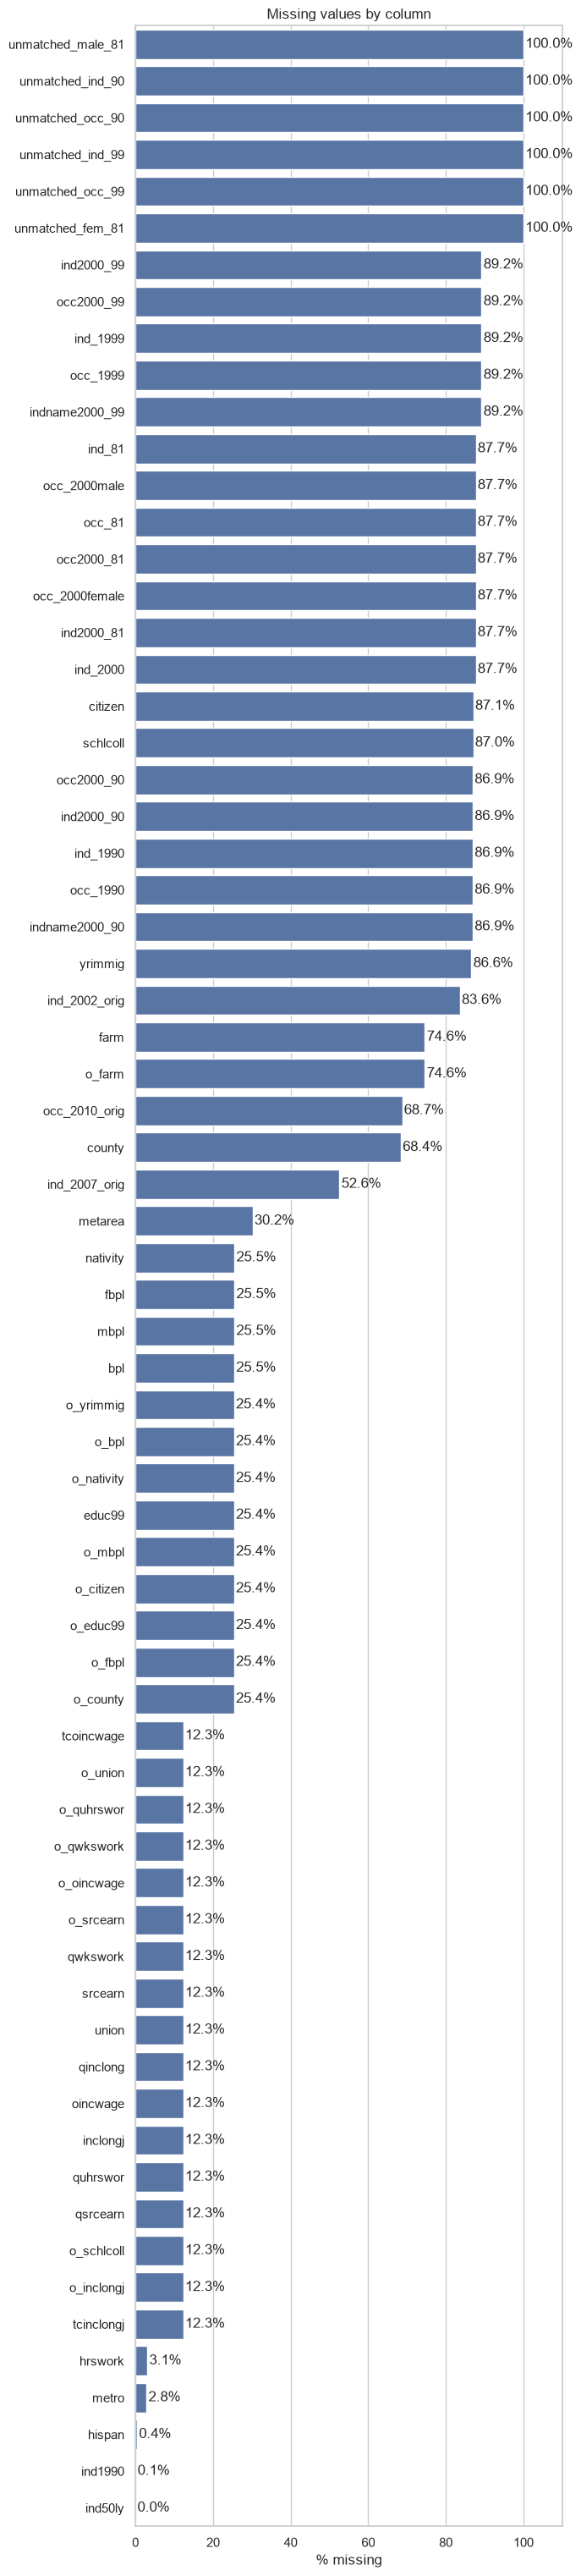

In [101]:
miss = df.isna().mean().mul(100).sort_values(ascending=False)
miss = miss[miss > 0]
print(miss.round(2).to_string())

fig, ax = plt.subplots(figsize=(7, max(2.5, 0.45 * len(miss))))
sns.barplot(x=miss.values, y=miss.index, color="#4c72b0", ax=ax)
for i, v in enumerate(miss.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
ax.set_xlabel("% missing"); ax.set_ylabel(""); ax.set_title("Missing values by column")
ax.set_xlim(0, max(100, miss.max() + 10))
savefig("01_missing_by_column")

### 3.1 Is the missingness tied to the survey year?
For each column with NAs: in how many survey years is it **entirely** missing / **entirely** observed?
A column where almost every year is all-or-nothing is missing *by design*.

,missing_%,years_fully_missing,years_fully_observed,n_years,share_of_years_all_or_nothing,structural_by_year
column,,,,,,
unmatched_male_81,100.0000,7,0,7,1.0000,True
unmatched_ind_90,100.0000,7,0,7,1.0000,True
unmatched_occ_90,100.0000,7,0,7,1.0000,True
unmatched_ind_99,100.0000,7,0,7,1.0000,True
unmatched_occ_99,100.0000,7,0,7,1.0000,True
...,...,...,...,...,...,...
hrswork,3.0658,0,7,7,1.0000,True
metro,2.8346,0,6,7,0.8571,False
hispan,0.4058,0,7,7,1.0000,True


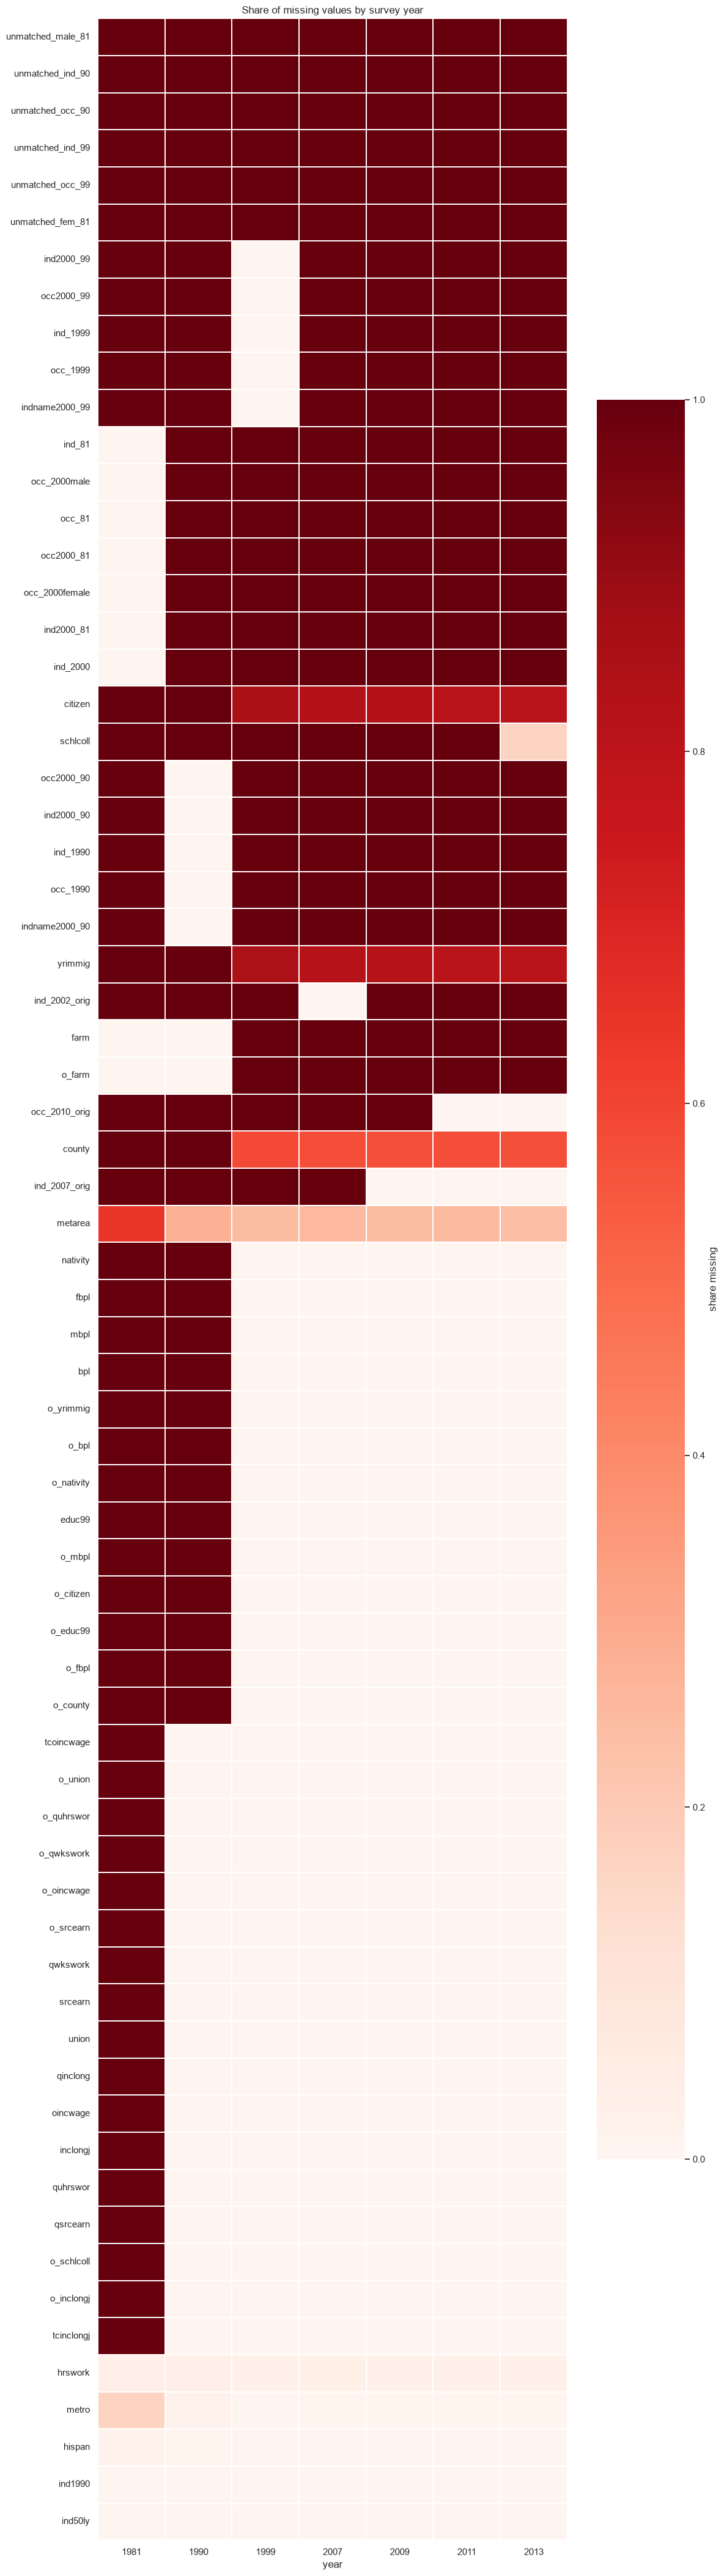

In [102]:
miss_cols = list(miss.index)
by_year = df[miss_cols].isna().groupby(df["year"]).mean()

rows = []
for c in miss_cols:
    s = by_year[c]
    all_or_nothing = ((s >= 0.95) | (s <= 0.05)).mean()
    rows.append({"column": c, "missing_%": miss[c], "years_fully_missing": int((s >= 0.95).sum()),
                 "years_fully_observed": int((s <= 0.05).sum()), "n_years": len(s),
                 "share_of_years_all_or_nothing": all_or_nothing,
                 "structural_by_year": all_or_nothing >= 0.9})
miss_report = pd.DataFrame(rows).set_index("column")
display(miss_report)

fig, ax = plt.subplots(figsize=(12, 0.6 * len(miss_cols) + 1.5))
sns.heatmap(by_year.T, cmap="Reds", vmin=0, vmax=1, cbar_kws={"label": "share missing"}, ax=ax, linewidths=0.2)
ax.set_title("Share of missing values by survey year"); ax.set_xlabel("year"); ax.set_ylabel("")
savefig("02_missing_by_year")

### 3.2 Treatment rules

| Situation | Treatment | Why |
|---|---|---|
| > 50 % missing (e.g. `citizen`) | **drop the column** | Too little information; imputing >50 % is fabrication |
| 1–50 % missing, tied to survey year (`nativity`, `educ99`, `union`) | **keep the rows**; fill with an explicit *Unknown* code (`-1` for nominal codes, `0` for the binary `union`) and add a `<col>_missing` indicator | Not missing at random; the indicator lets the model learn "not asked in that wave" instead of pretending we know the value |
| < 1 % missing (`hispan`) | **mode imputation** | Negligible share, no systematic pattern |

Dropping *rows* with NAs is rejected: it would delete entire survey years (≈ 25 % of the data for `educ99`) and
shift the time-trend analysis (RQ1).

In [103]:
DROP_THRESHOLD, RARE_THRESHOLD = 50.0, 1.0
WAGE_COLS = ["incwage", "incbus", "incfarm", "hrwage", "realhrwage", "lnrwg"]   # never imputed (rows with bad wages are handled in section 5)
UNKNOWN = -1                      # sentinel for "not asked / unknown" in nominal columns (real CPS codes are >= 0)

dropped_cols, flagged_cols, imputed_cols, flagged_fill = [], [], [], {}
for c in miss_cols:
    pct = miss[c]
    if c in WAGE_COLS:
        continue
    if pct > DROP_THRESHOLD:
        df = df.drop(columns=c); dropped_cols.append(c)
    elif pct >= RARE_THRESHOLD and miss_report.loc[c, "structural_by_year"]:
        df[f"{c}_missing"] = df[c].isna().astype("int8")
        is_binary = set(df[c].dropna().unique()) <= {0, 1}
        fill = 0 if is_binary else UNKNOWN          # binary 0/1 stays a valid dummy; nominal codes get an explicit Unknown level
        df[c] = df[c].fillna(fill); flagged_cols.append(c); flagged_fill[c] = fill
    else:
        mode = df[c].mode(dropna=True).iloc[0]
        df[c] = df[c].fillna(mode); imputed_cols.append((c, mode))

print("Dropped columns       :", dropped_cols)
print("Unknown-code + flag   :", flagged_cols)
print("Mode-imputed (<1 %)   :", imputed_cols)
print("Wage columns left untouched (handled in section 5):", [c for c in miss_cols if c in WAGE_COLS])
print("Remaining NaNs in df  :", int(df.isna().sum().sum()))

for c in dropped_cols:
    log_decision("Missing values", f"Dropped column `{c}` ({miss[c]:.1f}% missing).",
                 "More than half missing and collected only in a few survey years; cannot be imputed credibly.", "1 column")
for c in flagged_cols:
    log_decision("Missing values", f"`{c}` ({miss[c]:.1f}% missing): filled with {flagged_fill[c]} ({'0 = binary dummy' if flagged_fill[c] == 0 else 'explicit Unknown code'}) + indicator `{c}_missing`.",
                 "Missing by design (question not asked in some survey years), i.e. not at random. Imputing the mode/mean "
                 "would invent values; dropping rows would remove whole years and distort the 1981-2013 trend.",
                 f"{int(df[c + '_missing'].sum()):,} rows flagged")
for c, mode in imputed_cols:
    log_decision("Missing values", f"`{c}` ({miss[c]:.2f}% missing): mode imputation (value {mode}).",
                 "Negligible share of missing values with no year pattern; mode imputation changes nothing measurable.",
                 f"{miss[c] / 100 * len(df):,.0f} rows")

C:\Users\User\AppData\Local\Temp\ipykernel_17176\1920849102.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{c}_missing"] = df[c].isna().astype("int8")
C:\Users\User\AppData\Local\Temp\ipykernel_17176\1920849102.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{c}_missing"] = df[c].isna().astype("int8")
C:\Users\User\AppData\Local\Temp\ipykernel_17176\1920849102.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performanc

Dropped columns       : ['unmatched_male_81', 'unmatched_ind_90', 'unmatched_occ_90', 'unmatched_ind_99', 'unmatched_occ_99', 'unmatched_fem_81', 'ind2000_99', 'occ2000_99', 'ind_1999', 'occ_1999', 'indname2000_99', 'ind_81', 'occ_2000male', 'occ_81', 'occ2000_81', 'occ_2000female', 'ind2000_81', 'ind_2000', 'citizen', 'schlcoll', 'occ2000_90', 'ind2000_90', 'ind_1990', 'occ_1990', 'indname2000_90', 'yrimmig', 'ind_2002_orig', 'farm', 'o_farm', 'occ_2010_orig', 'county', 'ind_2007_orig']
Unknown-code + flag   : ['nativity', 'fbpl', 'mbpl', 'bpl', 'o_yrimmig', 'o_bpl', 'o_nativity', 'educ99', 'o_mbpl', 'o_citizen', 'o_educ99', 'o_fbpl', 'o_county', 'tcoincwage', 'o_union', 'o_quhrswor', 'o_qwkswork', 'o_oincwage', 'o_srcearn', 'qwkswork', 'srcearn', 'union', 'qinclong', 'oincwage', 'inclongj', 'quhrswor', 'qsrcearn', 'o_schlcoll', 'o_inclongj', 'tcinclongj', 'hrswork']
Mode-imputed (<1 %)   : [('metarea', np.float32(8840.0)), ('metro', np.float32(3.0)), ('hispan', np.float32(0.0)), ('in

### 3.3 A complete education variable
`educ99` is empty in ~25 % of rows (early years), but `ba` / `adv` (bachelor's / advanced degree dummies) are
fully populated. We derive a coarse but **complete** `edu_group` from them so that education — a key control for
RQ2/RQ3 — is available for every observation. `educ99` stays as the fine-grained variable (with an *Unknown* level).

In [104]:
if has("ba") and has("adv"):
    df["edu_group"] = np.select([df["adv"] == 1, df["ba"] == 1], ["Advanced degree", "Bachelor's"], default="Below bachelor's")
    print(df["edu_group"].value_counts(normalize=True).round(3))
    log_decision("Feature derivation", "Created `edu_group` (Below bachelor's / Bachelor's / Advanced degree) from `ba`, `adv`.",
                 "`educ99` is missing for whole survey years; `ba`/`adv` are complete, so every row keeps an education control.",
                 "1 new column")
else:
    print("ba/adv not found — skipping edu_group")

edu_group
Below bachelor's   0.6770
Bachelor's         0.2120
Advanced degree    0.1120
Name: proportion, dtype: float64


C:\Users\User\AppData\Local\Temp\ipykernel_17176\320497747.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["edu_group"] = np.select([df["adv"] == 1, df["ba"] == 1], ["Advanced degree", "Bachelor's"], default="Below bachelor's")


## 4. Logical consistency checks
Impossible or inconsistent values are fixed or removed *before* looking at outliers.

In [105]:
n0 = len(df)

# 4.1 sex / female dummy
assert set(df["sex"].unique()) <= {1, 2}, "unexpected sex codes"
if has("female"):
    inconsistent = int((df["female"] != (df["sex"] == 2).astype(int)).sum())
    print("female != (sex == 2):", inconsistent)
else:
    df["female"] = (df["sex"] == 2).astype("int8")
    print("`female` dummy created from `sex`")
df["female"] = df["female"].astype("int8")

# 4.2 ranges
print("\nage        :", df["age"].min(), "-", df["age"].max())
print("wkswork1   :", df["wkswork1"].min(), "-", df["wkswork1"].max(), "(valid 0-52)")
print("uhrswork   :", df["uhrswork"].min(), "-", df["uhrswork"].max(), "(valid 0-99)")
bad_hours = ~df["wkswork1"].between(0, 52) | ~df["uhrswork"].between(0, 99) | (df["age"] < 16)
print("rows with invalid age/hours/weeks:", int(bad_hours.sum()))
df = df.loc[~bad_hours].reset_index(drop=True)

# 4.3 negative potential experience (age - years of schooling - 6 can go below zero) -> clip at 0, recompute potexp2
n_neg = int((df["potexp"] < 0).sum())
pos = df["potexp"] > 0
pe = df["potexp"].astype("float64")                       # float64: small int dtypes would overflow when squared
scale = float((df.loc[pos, "potexp2"].astype("float64") / pe[pos] ** 2).median())     # 1.0, or 0.01 if potexp2 is /100
df["potexp"] = df["potexp"].clip(lower=0)
df["potexp2"] = (scale * df["potexp"].astype("float64") ** 2).astype("float32")
print(f"negative potexp: {n_neg:,} -> clipped to 0 (potexp2 = {scale:g} * potexp^2 recomputed)")

log_decision("Consistency", f"Removed {int(bad_hours.sum()):,} rows with age < 16 or impossible weeks/hours.",
             "Values outside the valid CPS ranges are data errors.", f"{int(bad_hours.sum()):,} rows")
log_decision("Consistency", f"Clipped {n_neg:,} negative `potexp` values to 0 and recomputed `potexp2`.",
             "Potential experience = age - schooling - 6 becomes negative when schooling is long relative to age; "
             "negative experience is meaningless, and `potexp2` must stay consistent with `potexp`.", f"{n_neg:,} rows")

# 4.4 does hrwage really equal annual wage / annual hours?
annual_hours = df["wkswork1"].astype("float64") * df["uhrswork"].astype("float64")   # float64 avoids int8 overflow
calc = df["incwage"].astype("float64") / annual_hours.replace(0, np.nan)
ok = np.isclose(calc, df["hrwage"].astype("float64"), rtol=0.02, equal_nan=False)
print(f"\nhrwage ≈ incwage / (wkswork1 * uhrswork) within 2 %: {ok.mean():.1%} of rows")

female != (sex == 2): 0

age        : 25 - 64
wkswork1   : 1 - 52 (valid 0-52)
uhrswork   : 1 - 99 (valid 0-99)
rows with invalid age/hours/weeks: 0
negative potexp: 0 -> clipped to 0 (potexp2 = 1 * potexp^2 recomputed)

hrwage ≈ incwage / (wkswork1 * uhrswork) within 2 %: 98.8% of rows


## 5. Target variable and non-positive wages

The target is **`log(realhrwage)`** (Mincer wage equation, see GPG-002). A logarithm is undefined for wages ≤ 0, so
those rows cannot be part of the regression sample.

In [106]:
bad_wage = df["realhrwage"].isna() | ~np.isfinite(df["realhrwage"]) | (df["realhrwage"] <= 0)
print(f"rows with realhrwage missing / <= 0 / inf: {int(bad_wage.sum()):,} ({bad_wage.mean():.2%})")
print("by sex:", df.loc[bad_wage, "female"].map({0: "male", 1: "female"}).value_counts().to_dict())
df = df.loc[~bad_wage].reset_index(drop=True)
log_decision("Target", f"Removed {int(bad_wage.sum()):,} rows with `realhrwage` missing or <= 0.",
             "log(wage) is undefined; zero hourly wages are unpaid/zero-hours artefacts rather than real wage offers.",
             f"{int(bad_wage.sum()):,} rows")

rows with realhrwage missing / <= 0 / inf: 0 (0.00%)
by sex: {}


## 6. Outlier analysis

### 6.1 CPS top-coding
The CPS caps (top-codes) reported annual wage income for confidentiality; the cap changes over time. We detect it
as "many rows sitting exactly on the yearly maximum of `incwage`".

C:\Users\User\AppData\Local\Temp\ipykernel_17176\3111820932.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  yr = pd.DataFrame({"max_incwage": g.max(), "n": g.size(), "n_at_max": df.assign(_m=df["incwage"] == g.transform("max"))


Years with a detected top-code: 1 of 7
Top-coded rows: 671 (0.19%)
Share top-coded by sex (%): {'men': 0.37, 'women': 0.02}


C:\Users\User\AppData\Local\Temp\ipykernel_17176\3111820932.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["top_coded"] = (df["year"].map(topcode_map).eq(df["incwage"])).astype("int8")


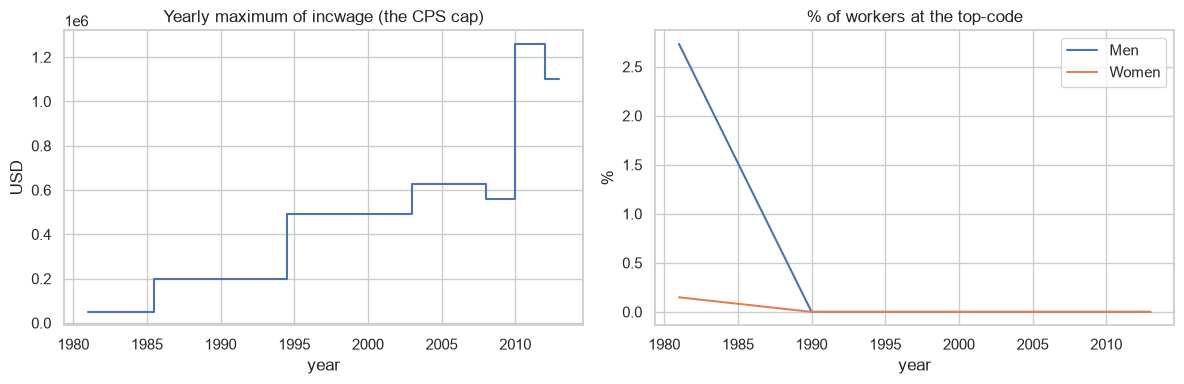

In [107]:
g = df.groupby("year")["incwage"]
yr = pd.DataFrame({"max_incwage": g.max(), "n": g.size(), "n_at_max": df.assign(_m=df["incwage"] == g.transform("max"))
                   .groupby("year")["_m"].sum()})
yr["topcoded_year"] = yr["n_at_max"] >= np.maximum(10, 0.0005 * yr["n"])
topcode_map = yr.loc[yr["topcoded_year"], "max_incwage"]

df["top_coded"] = (df["year"].map(topcode_map).eq(df["incwage"])).astype("int8")
print(f"Years with a detected top-code: {int(yr['topcoded_year'].sum())} of {len(yr)}")
print(f"Top-coded rows: {int(df['top_coded'].sum()):,} ({df['top_coded'].mean():.2%})")
tc_sex = df.groupby("female")["top_coded"].mean().mul(100).rename({0: "men", 1: "women"})
print("Share top-coded by sex (%):", tc_sex.round(2).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].step(yr.index, yr["max_incwage"], where="mid", color="#4c72b0")
axes[0].set_title("Yearly maximum of incwage (the CPS cap)"); axes[0].set_xlabel("year"); axes[0].set_ylabel("USD")
tc_year_sex = df.groupby(["year", "female"])["top_coded"].mean().unstack().mul(100)
tc_year_sex.columns = ["Men", "Women"]
tc_year_sex.plot(ax=axes[1], color=["#4c72b0", "#dd8452"])
axes[1].set_title("% of workers at the top-code"); axes[1].set_ylabel("%"); axes[1].set_xlabel("year")
savefig("03_topcoding")

**Decision: keep top-coded rows, add the flag `top_coded`.**
Men are over-represented at the cap (see right panel). Deleting those rows would remove predominantly high-earning men
and therefore **bias the gender gap downwards**. Instead the rows stay, are marked, and the top tail is handled by
winsorization on the log scale (next step); a sensitivity check without them is trivial via the flag.

In [108]:
log_decision("Outliers (top-coding)", f"Detected yearly top-codes of `incwage` and added flag `top_coded` ({int(df['top_coded'].sum()):,} rows); rows kept.",
             "Top-coding is censoring, not an error. Men are more often at the cap, so dropping these rows would understate the gender gap.",
             f"{int(df['top_coded'].sum()):,} rows flagged")

### 6.2 Extreme hourly wages
Annual wage / (weeks × weekly hours) explodes when hours are tiny, and collapses towards zero for near-zero income.
We look at the distribution on the log scale and apply the 3×IQR rule only as a *diagnostic*.

In [109]:
df["ln_realhrwage_raw"] = np.log(df["realhrwage"]).astype("float32")
x = df["ln_realhrwage_raw"]
q1, q3 = x.quantile([0.25, 0.75]); iqr = q3 - q1
lo_f, hi_f = q1 - 3 * iqr, q3 + 3 * iqr
n_iqr = int(((x < lo_f) | (x > hi_f)).sum())
print(f"3×IQR fences on ln(realhrwage): [{lo_f:.2f}, {hi_f:.2f}]  -> ${np.exp(lo_f):,.2f} .. ${np.exp(hi_f):,.2f}")
print(f"Rows outside the fences: {n_iqr:,} ({n_iqr / len(df):.2%})")
print(df["realhrwage"].describe(percentiles=[.001, .01, .05, .5, .95, .99, .999]).round(2).to_string())

3×IQR fences on ln(realhrwage): [0.02, 5.72]  -> $1.02 .. $303.45
Rows outside the fences: 140 (0.04%)
count   344,287.0000
mean         22.8900
std         506.4900
min           2.0000
0.1%          2.3100
1%            4.0300
5%            6.6000
50%          17.7000
95%          48.8400
99%          87.7000
99.9%       174.2800
max     294,610.9700


C:\Users\User\AppData\Local\Temp\ipykernel_17176\4093258269.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["ln_realhrwage_raw"] = np.log(df["realhrwage"]).astype("float32")


**Decision: winsorize `ln(realhrwage)` at the 1st and 99th percentiles** (values beyond are *clipped*, not deleted).
* No observations are lost (important for time-trend and subgroup analysis).
* The OLS / distance-based models used later are sensitive to a handful of absurd hourly wages caused by tiny hours.
* Both versions are kept: `ln_realhrwage_raw` and `ln_realhrwage` (winsorized, the modelling target).

The 1/99 bounds are computed on the full cleaned sample (a descriptive clipping rule; the effect on the train/test
split is negligible compared with fitting a scaler, which *is* done on the training set only — see section 9).

C:\Users\User\AppData\Local\Temp\ipykernel_17176\1887513506.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["ln_realhrwage"] = x.clip(lo_b, hi_b).astype("float32")


Winsorization bounds: ln = [1.394, 4.474]  ->  $4.03 .. $87.70 per hour
Values clipped: 6,872 (2.00%)


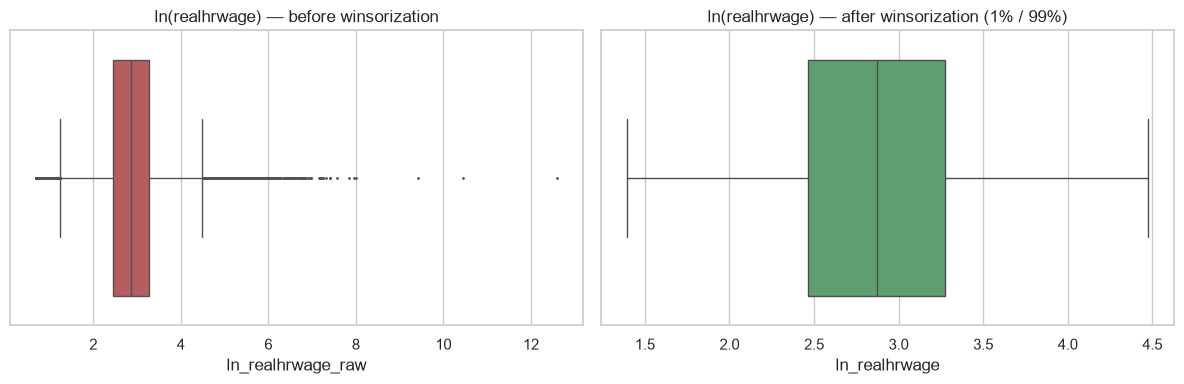

In [110]:
P_LO, P_HI = 0.01, 0.99
lo_b, hi_b = x.quantile([P_LO, P_HI])
df["ln_realhrwage"] = x.clip(lo_b, hi_b).astype("float32")
n_clip = int(((x < lo_b) | (x > hi_b)).sum())
print(f"Winsorization bounds: ln = [{lo_b:.3f}, {hi_b:.3f}]  ->  ${np.exp(lo_b):,.2f} .. ${np.exp(hi_b):,.2f} per hour")
print(f"Values clipped: {n_clip:,} ({n_clip / len(df):.2%})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["ln_realhrwage_raw"], ax=axes[0], color="#c44e52", fliersize=1)
axes[0].set_title("ln(realhrwage) — before winsorization")
sns.boxplot(x=df["ln_realhrwage"], ax=axes[1], color="#55a868", fliersize=1)
axes[1].set_title("ln(realhrwage) — after winsorization (1% / 99%)")
savefig("04_outliers_winsorization")

log_decision("Outliers (extreme wages)", f"Winsorized ln(realhrwage) at the {P_LO:.0%}/{P_HI:.0%} percentiles "
             f"(${np.exp(lo_b):,.2f}–${np.exp(hi_b):,.2f}/h); {n_clip:,} values clipped, none deleted.",
             "Hourly wages derived from tiny hours/near-zero income are implausible; clipping limits their leverage on "
             "regression coefficients while keeping every worker in the sample. Raw version retained as `ln_realhrwage_raw`.",
             f"{n_clip:,} values")

## 7. Variable transformation: `log(realhrwage)`
Wages are strongly right-skewed. The log transform (a) makes the distribution close to symmetric, (b) lets regression
coefficients be read as approximate % differences — exactly what the gender-gap question needs.

C:\Users\User\AppData\Local\Temp\ipykernel_17176\2971782094.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["ln_incwage"] = np.where(df["incwage"] > 0, np.log(df["incwage"].clip(lower=1)), np.nan).astype("float32")


,variable,skewness,kurtosis
0,realhrwage,572.4799,"332,461.5312"
1,ln(realhrwage) raw,0.1891,1.1051
2,ln(realhrwage) winsorized,0.0790,-0.0786


corr(lnrwg from dataset, our ln_realhrwage_raw) = 1.0000


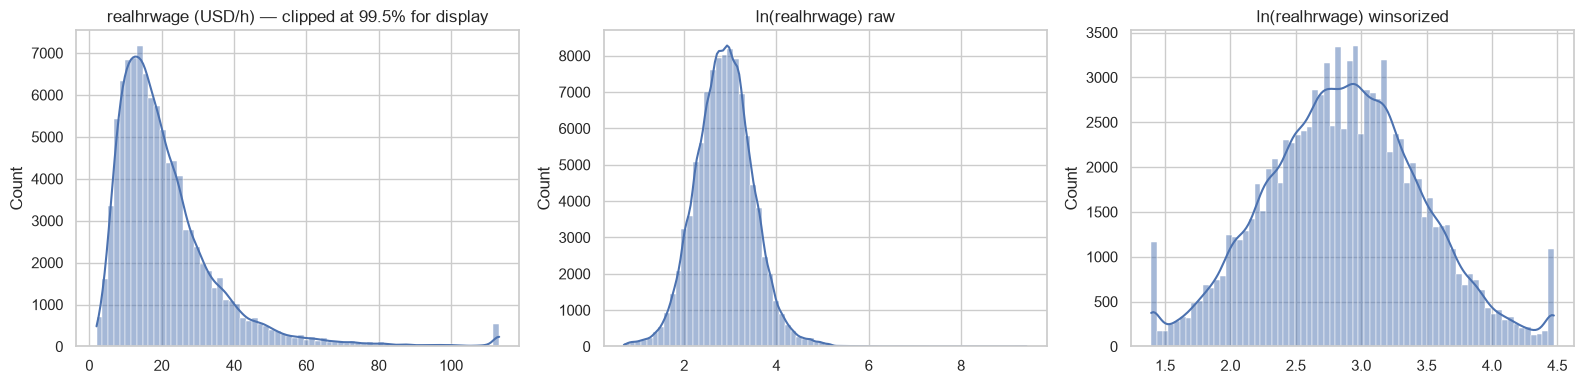

In [111]:
df["ln_incwage"] = np.where(df["incwage"] > 0, np.log(df["incwage"].clip(lower=1)), np.nan).astype("float32")

sk = pd.DataFrame({
    "variable": ["realhrwage", "ln(realhrwage) raw", "ln(realhrwage) winsorized"],
    "skewness": [stats.skew(df["realhrwage"]), stats.skew(df["ln_realhrwage_raw"]), stats.skew(df["ln_realhrwage"])],
    "kurtosis": [stats.kurtosis(df["realhrwage"]), stats.kurtosis(df["ln_realhrwage_raw"]), stats.kurtosis(df["ln_realhrwage"])],
})
display(sk)

if has("lnrwg"):
    both = df[["lnrwg", "ln_realhrwage_raw"]].dropna()
    print(f"corr(lnrwg from dataset, our ln_realhrwage_raw) = {both.corr().iloc[0, 1]:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sample = df.sample(min(len(df), 100_000), random_state=RANDOM_STATE)
for ax, col, ttl in zip(axes, ["realhrwage", "ln_realhrwage_raw", "ln_realhrwage"],
                        ["realhrwage (USD/h) — clipped at 99.5% for display", "ln(realhrwage) raw", "ln(realhrwage) winsorized"]):
    vals = sample[col] if col != "realhrwage" else sample[col].clip(upper=sample[col].quantile(0.995))
    sns.histplot(vals, bins=70, kde=True, ax=ax, color="#4c72b0"); ax.set_title(ttl); ax.set_xlabel("")
savefig("05_target_transformation")

log_decision("Transformation", "Target = `ln_realhrwage` (natural log of real hourly wage, winsorized); also added `ln_incwage`.",
             f"Skewness drops from {sk.loc[0, 'skewness']:.2f} to {sk.loc[2, 'skewness']:.2f}; coefficients on the log scale are "
             "approximate % wage differences (Mincer equation), the standard in wage-gap research.", "2 new columns")

## 8. Aggregation and sampling

* **Sampling – not needed for modelling.** ~340k rows × ~100 columns fits comfortably in memory, and dropping rows would
  only lose subgroup precision. Only *expensive plots* (KDE, scatter) use a random subsample inside the EDA notebook.
* **Aggregation – year × sex summary** for the time-trend question (RQ1). The CPS supplemental weight `wtsupp`
  makes the means representative of the US population, so we store weighted statistics. The table is tiny and
  is committed to `docs/results/`.

In [112]:
if has("wtsupp"):
    w_col = "wtsupp"
else:
    df["wtsupp"] = 1.0; w_col = "wtsupp"      # fall back to unweighted

tmp = df[["year", "female", "realhrwage", "ln_realhrwage", w_col]].copy()
tmp["w_ln"] = tmp["ln_realhrwage"] * tmp[w_col]
tmp["w_rw"] = tmp["realhrwage"] * tmp[w_col]
grp = tmp.groupby(["year", "female"])
agg = pd.DataFrame({"n": grp.size(),
                    "mean_ln_realhrwage_w": grp["w_ln"].sum() / grp[w_col].sum(),
                    "mean_realhrwage_w": grp["w_rw"].sum() / grp[w_col].sum(),
                    "median_realhrwage": grp["realhrwage"].median()}).reset_index()
agg.to_csv(RES_DIR / "agg_year_sex.csv", index=False)
display(agg.head(6))

log_decision("Aggregation / sampling", "No row sampling for modelling; saved weighted year × sex summary to `docs/results/agg_year_sex.csv`.",
             "Full data fits in memory (subsampling would only reduce precision). The aggregate supports the time-trend question "
             "(RQ1) and keeps the survey weights.", f"{len(agg)} aggregate rows")

,year,female,n,mean_ln_realhrwage_w,mean_realhrwage_w,median_realhrwage
0,1981,0,23527,2.9562,22.1383,19.8448
1,1981,1,18852,2.4781,13.7929,11.6688
2,1990,0,23229,2.9309,22.2912,19.0872
3,1990,1,21804,2.5898,15.6072,13.3121
4,1999,0,18870,2.9789,23.7559,19.5650
5,1999,1,18274,2.7058,17.9488,14.6737


### 8.1 Save the cleaned (unscaled, un-encoded) dataset for EDA

In [113]:
meta_cols = [c for c in ["serial"] if c in df.columns]
clean = df.drop(columns=meta_cols)
clean.to_csv(PROCESSED / "cps_clean.csv.gz", index=False, compression="gzip")
CLEAN_ROWS, CLEAN_COLS = clean.shape
print(f"Saved cps_clean.csv.gz: {CLEAN_ROWS:,} rows x {CLEAN_COLS} columns")

Saved cps_clean.csv.gz: 344,287 rows x 236 columns


## 9. Model-ready dataset: encoding, scaling, split

### 9.1 Which columns are *not* features

| Dropped from the feature matrix | Reason |
|---|---|
| `incwage`, `hrwage`, `realhrwage`, `lnrwg`, `ln_incwage`, `ln_realhrwage_raw`, `incbus`, `incfarm` | **target leakage** — they are the target or algebraically derived from it |
| `serial`, `wtsupp` | identifier / survey weight (weight is kept as a separate column `sample_weight`) |
| `sex` | duplicate of `female` (perfectly collinear) |
| `empstat`, `labforce` and any constant column | zero variance by sample definition |
| `occ1990`, `ind1990`, `statefip` | hundreds of nominal codes; the occupation/industry dummies, `adj_occ2name` and region dummies carry the same information at a usable level (target/frequency encoding is a GPG-005 topic) |
| `top_coded` | derived from the wage, therefore leakage |

In [114]:
TARGET = "ln_realhrwage"
LEAKAGE = ["incwage", "hrwage", "realhrwage", "lnrwg", "ln_incwage", "ln_realhrwage_raw", "incbus", "incfarm", "top_coded"]
IDS = ["serial", "wtsupp", "sex"]
HIGH_CARD = ["occ1990", "ind1990", "statefip"]

import re
# The real CPS file has many raw helper columns: o_* (original unedited values), q* (imputation flags)
# and other income variables. None of them may be used as predictors (leakage / not meaningful).
extra_drop = [c for c in df.columns
              if c not in LEAKAGE + [TARGET]
              and (c.startswith("o_")
                   or re.match(r"^q(wkswork|uhrswor|incbus|incfarm|inclong|srcearn|oincwage)", c)
                   or re.search(r"inc|earn|wage", c))]
print(f"Extra columns excluded from the feature matrix: {len(extra_drop)}")
print(extra_drop)
log_decision("Feature selection", f"Excluded {len(extra_drop)} raw helper / income columns (o_*, q* flags, other income variables) from the features.",
             "o_* hold unedited original values, q* are imputation flags; other income columns (e.g. inclongj, srcearn) are target leakage.",
             f"{len(extra_drop)} columns")
code_drop = ["un_lnrealwg", "hwtsupp", "metro", "metarea", "pernum", "relate", "bpl", "mbpl", "fbpl", "sch",
             "occ", "occ1950", "ind", "ind1950", "occly", "occ50ly", "indly", "ind50ly", "classwly", "ftype",
             "origrace", "educorig", "adj_occ", "adj_ind", "adj_ind2", "adj_occ2", "occ_orig", "ind_orig"]
log_decision("Feature selection", "Excluded `un_lnrealwg` (uncensored log wage = target leakage) and 25 nominal code / id columns.",
             "un_lnrealwg is the target itself; the code columns are nominal labels (occupation, industry, birthplace, ...) "
             "that would be wrongly treated as numbers; occupation and industry are already represented by dummies and adj_occ2name.",
             f"{len(code_drop)} columns")
X = df.drop(columns=[c for c in LEAKAGE + IDS + HIGH_CARD + extra_drop + code_drop if c in df.columns] + [TARGET])
const_cols = [c for c in X.columns if X[c].nunique(dropna=False) <= 1]
X = X.drop(columns=const_cols)
print("Constant columns dropped:", const_cols)

# classify the remaining columns
binary_cols = [c for c in X.select_dtypes(include=[np.number]).columns if set(X[c].unique()) <= {0, 1}]
continuous_cols = [c for c in ["age", "potexp", "potexp2", "wkswork1", "uhrswork", "year",
                               "numprec", "hrswork", "annhrs", "wkswork2", "inflate", "union", "perconexp"] if c in X.columns]
text_cols = list(X.select_dtypes(exclude=[np.number]).columns)
nominal_cols = [c for c in ["race", "marst", "hispan", "nativity", "classwkr", "region", "educ99"] if c in X.columns] + text_cols
# edu_group is derived from ba/adv -> its one-hot would be a linear combination of them
if "edu_group" in nominal_cols and has("ba") and has("adv"):
    nominal_cols.remove("edu_group"); X = X.drop(columns="edu_group")
    log_decision("Encoding", "Did not one-hot `edu_group` (kept `ba`, `adv` dummies instead).",
                 "`edu_group` is an exact function of `ba`/`adv`; its dummies would be perfectly collinear with them. "
                 "`edu_group` remains in `cps_clean.csv.gz` for EDA.", "1 column")
# nominal columns with an explicit Unknown level (-1) already encode "missing" -> the extra indicator would be redundant
for c in flagged_cols:
    if c in nominal_cols and f"{c}_missing" in X.columns:
        X = X.drop(columns=f"{c}_missing")
# `region` is redundant if region dummies already exist
if any(c in X.columns for c in ["northeast", "midwest", "south", "west"]) and "region" in nominal_cols:
    nominal_cols.remove("region"); X = X.drop(columns="region")
    log_decision("Encoding", "Did not one-hot `region` (region dummies already exist).", "Avoids a duplicated, perfectly collinear block.", "1 column")
print("binary     :", len(binary_cols), "| continuous:", continuous_cols)
print("nominal    :", nominal_cols)

Extra columns excluded from the feature matrix: 99
['inclongj', 'oincwage', 'srcearn', 'quhrswor', 'qwkswork', 'qincbus', 'qincfarm', 'qinclong', 'qincwage', 'qsrcearn', 'o_numprec', 'o_hwtsupp', 'o_gq', 'o_region', 'o_statefip', 'o_metro', 'o_metarea', 'o_county', 'o_month', 'o_pernum', 'o_wtsupp', 'o_relate', 'o_age', 'o_sex', 'o_race', 'o_marst', 'o_popstat', 'o_bpl', 'o_yrimmig', 'o_citizen', 'o_mbpl', 'o_fbpl', 'o_nativity', 'o_hispan', 'o_educ', 'o_educ99', 'o_schlcoll', 'o_empstat', 'o_labforce', 'o_occ', 'o_occ1990', 'o_ind1990', 'o_occ1950', 'o_ind', 'o_ind1950', 'o_classwkr', 'o_occly', 'o_occ50ly', 'o_indly', 'o_ind50ly', 'o_classwly', 'o_wkswork1', 'o_wkswork2', 'o_hrswork', 'o_uhrswork', 'o_union', 'o_incwage', 'o_incbus', 'o_incfarm', 'o_inclongj', 'o_oincwage', 'o_srcearn', 'o_ftype', 'o_quhrswor', 'o_qwkswork', 'o_qincbus', 'o_qincfarm', 'o_qincwage', 'niincwage', 'incwageman', 'tcoincwage', 'tcinclongj', 'tcincwage', 'uncenrealhrwage', 'wagesamp', 'o_yrimmig_missing', 

### 9.2 Categorical encoding
* Existing 0/1 dummies and the missing-indicators stay as they are.
* Nominal codes (`race`, `marst`, `hispan`, `nativity`, `classwkr`, `educ99`) and text columns (`edu_group`, `adj_occ2name`)
  are **one-hot encoded** (`drop_first=True`). Their numeric codes are *labels*, not quantities — a linear model would
  wrongly treat race code 651 as "bigger" than 100. The `-1` Unknown level becomes its own category.
* `drop_first=True` removes one reference level per variable to avoid the dummy-variable trap.

In [115]:
too_wide = [c for c in nominal_cols if X[c].nunique() > 60]
nominal_cols = [c for c in nominal_cols if c not in too_wide]
if too_wide:
    print("Skipped (cardinality > 60):", too_wide); X = X.drop(columns=too_wide)

X_enc = pd.get_dummies(X, columns=nominal_cols, drop_first=True, dtype="int8")
print(f"Columns before/after one-hot: {X.shape[1]} -> {X_enc.shape[1]}")

log_decision("Encoding", f"One-hot encoded {len(nominal_cols)} nominal variables ({', '.join(nominal_cols)}) with drop_first=True; "
             "binary dummies kept as-is.",
             "Codes such as race=651 or educ99=15 are category labels without numeric meaning; one-hot avoids imposing a false order. "
             "drop_first removes the reference level (dummy-variable trap).", f"{X.shape[1]} -> {X_enc.shape[1]} columns")

Columns before/after one-hot: 77 -> 117


### 9.3 Perfect-collinearity check
Exhaustive dummy groups (e.g. a full set of occupation dummies that sums to 1 *plus* `adj_occ2name` one-hot) are linearly
dependent with the intercept and break OLS / inflate coefficient variance. We detect dependent columns with a
Gram–Schmidt pass on a 30k-row sample and drop them (the dropped level simply becomes the reference).

In [116]:
def dependent_columns(frame, n=30_000, tol=1e-6, seed=RANDOM_STATE):
    s = frame.sample(min(n, len(frame)), random_state=seed).to_numpy(dtype=np.float64)
    s = s - 0.0
    Q = [np.ones(len(s)) / np.sqrt(len(s))]        # intercept
    dropped = []
    for j in range(s.shape[1]):
        v = s[:, j].copy(); norm0 = np.linalg.norm(v)
        if norm0 == 0:
            dropped.append(frame.columns[j]); continue
        for q in Q:
            v -= q * (q @ v)
        if np.linalg.norm(v) < tol * norm0:
            dropped.append(frame.columns[j])
        else:
            Q.append(v / np.linalg.norm(v))
    return dropped

# keep the key variable first so that it is never the column that gets dropped
X_enc = X_enc[["female"] + [c for c in X_enc.columns if c != "female"]]
dep = dependent_columns(X_enc)
print("Linearly dependent columns dropped:", dep)
X_enc = X_enc.drop(columns=dep)
if dep:
    log_decision("Encoding", f"Dropped {len(dep)} linearly dependent dummy column(s): {', '.join(dep)}.",
                 "These columns are exact linear combinations of other columns and the intercept (exhaustive dummy sets); "
                 "keeping them makes OLS ill-defined.", f"{len(dep)} columns")

Linearly dependent columns dropped: ['othrace', 'west', 'publicadmin', 'lehs', 'hrswork_missing', 'race_2', 'race_3', 'race_4', 'hispan_1.0', 'adj_occ2name_Business Operators', 'adj_occ2name_Community and Social Workers', 'adj_occ2name_Computer and Math Technicians', 'adj_occ2name_Consruction, Extraction, Installation', 'adj_occ2name_Farming, Fishing & Forestry', 'adj_occ2name_Lawyers, Judges,Physicans and dentists', 'adj_occ2name_Managers', 'adj_occ2name_Office and Admin Support', 'adj_occ2name_Production', 'adj_occ2name_Protective Service adj_occupations', 'adj_occ2name_Transportation and materials moving', 'adj_occ2name_financial Operators']


### 9.4 Train / test split and scaling
Scaling must be **fitted on the training data only**, otherwise information from the test set leaks into the model.
So we split first (80 / 20, stratified by `female` so both parts keep the same sex ratio), then fit `StandardScaler`
on the continuous columns of the training part and apply it to both.

*Which models need it?* Regularized linear models (Ridge/Lasso), KNN, SVM and neural nets do; tree ensembles are
invariant. Binary dummies are **not** scaled (their 0/1 scale is already interpretable).

In [117]:
y = df.loc[X_enc.index, TARGET]
weights = df.loc[X_enc.index, "wtsupp"].rename("sample_weight")

X_tr, X_te, y_tr, y_te, w_tr, w_te = train_test_split(
    X_enc, y, weights, test_size=0.20, random_state=RANDOM_STATE, stratify=X_enc["female"])

scale_cols = [c for c in continuous_cols if c in X_enc.columns]
scaler = StandardScaler().fit(X_tr[scale_cols])
X_tr = X_tr.copy(); X_te = X_te.copy()
X_tr[scale_cols] = scaler.transform(X_tr[scale_cols]).astype("float32")
X_te[scale_cols] = scaler.transform(X_te[scale_cols]).astype("float32")

print("Scaled columns:", scale_cols)
print(pd.DataFrame({"mean": X_tr[scale_cols].mean(), "std": X_tr[scale_cols].std()}).round(3))
print(f"\ntrain: {X_tr.shape}   test: {X_te.shape}")
print("female share  train / test:", round(X_tr["female"].mean(), 4), "/", round(X_te["female"].mean(), 4))

log_decision("Scaling", f"StandardScaler on {', '.join(scale_cols)} — fitted on the 80 % training split only, applied to train and test. Dummies not scaled.",
             "Put continuous features on a common scale for regularized/distance-based models; fitting on train only prevents "
             "test-set leakage. Tree models are unaffected, so the unscaled `cps_clean.csv.gz` is kept as well.", f"{len(scale_cols)} columns")
log_decision("Train/test split", f"80/20 split stratified by `female` (random_state={RANDOM_STATE}): train {len(X_tr):,} / test {len(X_te):,} rows.",
             "Required so that scaling (and later model selection) is evaluated on unseen data; stratification keeps the sex ratio equal.", "")

Scaled columns: ['age', 'potexp', 'potexp2', 'wkswork1', 'uhrswork', 'year', 'numprec', 'hrswork', 'annhrs', 'wkswork2', 'inflate', 'union', 'perconexp']
             mean    std
age        0.0000 1.0000
potexp     0.0000 1.0000
potexp2    0.0000 1.0000
wkswork1   0.0000 1.0000
uhrswork  -0.0000 1.0000
year      -0.0000 1.0000
numprec    0.0000 1.0000
hrswork   -0.0000 1.0000
annhrs    -0.0000 1.0000
wkswork2  -0.0000 1.0000
inflate    0.0000 1.0000
union     -0.0000 1.0000
perconexp -0.0000 1.0000

train: (275429, 96)   test: (68858, 96)
female share  train / test: 0.4891 / 0.489


### 9.5 Final validation and save

In [119]:
for name, part in [("train", X_tr), ("test", X_te)]:
    assert not part.isna().any().any(), f"NaN in {name}"
    assert np.isfinite(part.to_numpy(dtype=float)).all(), f"inf in {name}"
    assert all(pd.api.types.is_numeric_dtype(t) for t in part.dtypes), f"non-numeric column in {name}"
assert not y_tr.isna().any() and not y_te.isna().any()
leak = [c for c in X_tr.columns if re.search(r"wage|lnrwg|inc|earn|realwg", c)]
assert not leak, f"possible target leakage: {leak}"
print("All checks passed: no NaN / inf, all numeric, no wage-derived columns among the features.")

train = pd.concat([X_tr, w_tr.loc[X_tr.index], y_tr.rename(TARGET)], axis=1)
test = pd.concat([X_te, w_te.loc[X_te.index], y_te.rename(TARGET)], axis=1)
train.to_csv(PROCESSED / "cps_model_train.csv.gz", index=False, compression="gzip")
test.to_csv(PROCESSED / "cps_model_test.csv.gz", index=False, compression="gzip")
joblib.dump(scaler, PROCESSED / "scaler.joblib")
with open(PROCESSED / "model_features.json", "w") as fh:
    json.dump({"target": TARGET, "weight": "sample_weight", "features": list(X_tr.columns), "scaled_columns": scale_cols}, fh, indent=2)
print(f"Saved model-ready files: {len(X_tr.columns)} features")

All checks passed: no NaN / inf, all numeric, no wage-derived columns among the features.
Saved model-ready files: 96 features


## 10. Summary and decision log

In [120]:
summary = pd.DataFrame({
    "stage": ["Raw CSV", "After cleaning (cps_clean.csv.gz)", "Model-ready features"],
    "rows": [RAW_ROWS, CLEAN_ROWS, len(X_enc)],
    "columns": [RAW_COLS, CLEAN_COLS, X_enc.shape[1]],
})
display(summary)
print(f"Rows removed in total: {RAW_ROWS - CLEAN_ROWS:,} ({(RAW_ROWS - CLEAN_ROWS) / RAW_ROWS:.2%})")

decision_df = pd.DataFrame(DECISIONS)
pd.set_option("display.max_colwidth", 140)
display(decision_df)

,stage,rows,columns
0,Raw CSV,344287,233
1,After cleaning (cps_clean.csv.gz),344287,236
2,Model-ready features,344287,96


Rows removed in total: 0 (0.00%)


,Step,Decision,Rationale,Rows/cols affected
0,Duplicates,Dropped 0 exact duplicate rows (kept first occurrence).,A row identical in all columns incl. household id and survey weight is a duplicated record; keeping it would double-count that worker in...,0 rows
1,Missing values,Dropped column `unmatched_male_81` (100.0% missing).,More than half missing and collected only in a few survey years; cannot be imputed credibly.,1 column
2,Missing values,Dropped column `unmatched_ind_90` (100.0% missing).,More than half missing and collected only in a few survey years; cannot be imputed credibly.,1 column
3,Missing values,Dropped column `unmatched_occ_90` (100.0% missing).,More than half missing and collected only in a few survey years; cannot be imputed credibly.,1 column
4,Missing values,Dropped column `unmatched_ind_99` (100.0% missing).,More than half missing and collected only in a few survey years; cannot be imputed credibly.,1 column
...,...,...,...,...
80,Encoding,Did not one-hot `region` (region dummies already exist).,"Avoids a duplicated, perfectly collinear block.",1 column
81,Encoding,"One-hot encoded 7 nominal variables (race, marst, hispan, nativity, classwkr, educ99, adj_occ2name) with drop_first=True; binary dummies...",Codes such as race=651 or educ99=15 are category labels without numeric meaning; one-hot avoids imposing a false order. drop_first remov...,77 -> 117 columns
82,Encoding,"Dropped 21 linearly dependent dummy column(s): othrace, west, publicadmin, lehs, hrswork_missing, race_2, race_3, race_4, hispan_1.0, ad...",These columns are exact linear combinations of other columns and the intercept (exhaustive dummy sets); keeping them makes OLS ill-defined.,21 columns
83,Scaling,"StandardScaler on age, potexp, potexp2, wkswork1, uhrswork, year, numprec, hrswork, annhrs, wkswork2, inflate, union, perconexp — fitted...",Put continuous features on a common scale for regularized/distance-based models; fitting on train only prevents test-set leakage. Tree m...,13 columns


### Write the decision log to `docs/results/GPG-003_results.md`
Copy its content into the *Proposed Solution* section of `docs/GPG-003.md` (the template there already has the structure).

In [121]:
def md_escape(s):
    return str(s).replace("|", "\\|").replace("\n", " ")

lines = ["# GPG-003 — auto-generated results (from `notebooks/GPG-003_preprocessing.ipynb`)", "",
         f"- Raw data: **{RAW_ROWS:,} rows × {RAW_COLS} columns**",
         f"- After cleaning: **{CLEAN_ROWS:,} rows × {CLEAN_COLS} columns** ({RAW_ROWS - CLEAN_ROWS:,} rows removed, "
         f"{(RAW_ROWS - CLEAN_ROWS) / RAW_ROWS:.2%})",
         f"- Model-ready: **{X_enc.shape[1]} features**; train {len(X_tr):,} / test {len(X_te):,} rows; target `{TARGET}`", "",
         "| Step | Decision | Rationale | Affected |", "|---|---|---|---|"]
for d in DECISIONS:
    lines.append(f"| {md_escape(d['Step'])} | {md_escape(d['Decision'])} | {md_escape(d['Rationale'])} | {md_escape(d['Rows/cols affected'])} |")
(RES_DIR / "GPG-003_results.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("Wrote", RES_DIR / "GPG-003_results.md")

Wrote c:\Users\User\Data-mining-Final-Project\docs\results\GPG-003_results.md
